In [3]:
import pandas as pd
import os

# Check uploaded files
print(os.listdir("/content"))

# Load datasets (filenames must match exactly)
adult_df = pd.read_csv("/content/adult.csv")
temp_df = pd.read_csv("/content/1_Daily_minimum_temps.csv")
cancer_df = pd.read_csv("/content/data.csv")
wine_df = pd.read_csv("/content/winequality-red.csv")

# Display dataset dimensions
print("\nAdult Census Income:", adult_df.shape)
print("Daily Minimum Temperatures:", temp_df.shape)
print("Breast Cancer Wisconsin:", cancer_df.shape)
print("Red Wine Quality:", wine_df.shape)


['.config', 'adult.csv', '1_Daily_minimum_temps.csv', 'winequality-red.csv', 'data.csv', '.ipynb_checkpoints', 'sample_data']

Adult Census Income: (32561, 15)
Daily Minimum Temperatures: (3650, 2)
Breast Cancer Wisconsin: (569, 33)
Red Wine Quality: (1599, 12)


In [4]:
datasets = {
    "Adult Census Income": adult_df,
    "Daily Minimum Temperatures": temp_df,
    "Breast Cancer Wisconsin": cancer_df,
    "Red Wine Quality": wine_df
}

for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("Missing values:", df.isnull().sum().sum())
    print(df.head(2))



--- Adult Census Income ---
Shape: (32561, 15)
Columns: ['age', 'workclass', 'fnlwgt', 'education', 'education.num', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'capital.gain', 'capital.loss', 'hours.per.week', 'native.country', 'income']
Missing values: 0
   age workclass  fnlwgt education  education.num marital.status  \
0   90         ?   77053   HS-grad              9        Widowed   
1   82   Private  132870   HS-grad              9        Widowed   

        occupation   relationship   race     sex  capital.gain  capital.loss  \
0                ?  Not-in-family  White  Female             0          4356   
1  Exec-managerial  Not-in-family  White  Female             0          4356   

   hours.per.week native.country income  
0              40  United-States  <=50K  
1              18  United-States  <=50K  

--- Daily Minimum Temperatures ---
Shape: (3650, 2)
Columns: ['Date', 'Temp']
Missing values: 0
       Date  Temp
0  01/01/81  20.7
1  01/02/81  17.9


In [5]:
import numpy as np

cancer_df = cancer_df.drop(
    columns=["id", "Unnamed: 32"],
    errors="ignore"
)

adult_df = adult_df.replace("?", np.nan)

temp_df["Date"] = pd.to_datetime(
    temp_df["Date"], format="%m/%d/%y"
)

for name, df in {
    "Adult": adult_df,
    "Temperature": temp_df,
    "Breast Cancer": cancer_df,
    "Red Wine": wine_df
}.items():
    print(name, df.shape)
    print("Missing values:", df.isnull().sum().sum())


Adult (32561, 15)
Missing values: 4262
Temperature (3650, 2)
Missing values: 0
Breast Cancer (569, 31)
Missing values: 0
Red Wine (1599, 12)
Missing values: 0


In [6]:
# 1. Breast Cancer: classification
X_cancer = cancer_df.drop(columns=["diagnosis"])
y_cancer = cancer_df["diagnosis"].map({"B": 0, "M": 1})

# 2. Red Wine: regression
X_wine = wine_df.drop(columns=["quality"])
y_wine = wine_df["quality"]

# 3. Adult Income: classification (Mapping target strings to 0 and 1 to fix metric NaNs)
X_adult = adult_df.drop(columns=["income"])
y_adult = adult_df["income"].str.strip().str.replace(".", "", regex=False).map({"<=50K": 0, ">50K": 1})

# 4. Temperature: forecasting the next day's temperature
temp_df = temp_df.sort_values("Date").reset_index(drop=True)
X_temp = pd.DataFrame({
    "previous_day_temp": temp_df["Temp"].shift(1)
})
y_temp = temp_df["Temp"]

# Remove the first row, which has no previous-day temperature
X_temp = X_temp.iloc[1:].reset_index(drop=True)
y_temp = y_temp.iloc[1:].reset_index(drop=True)

print("Breast Cancer:", X_cancer.shape, y_cancer.shape)
print("Red Wine:", X_wine.shape, y_wine.shape)
print("Adult Income:", X_adult.shape, y_adult.shape)
print("Temperature:", X_temp.shape, y_temp.shape)

Breast Cancer: (569, 30) (569,)
Red Wine: (1599, 11) (1599,)
Adult Income: (32561, 14) (32561,)
Temperature: (3649, 1) (3649,)


In [7]:
from sklearn.model_selection import (
    StratifiedKFold,
    KFold,
    TimeSeriesSplit,
    cross_validate
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    mean_absolute_error, mean_squared_error, r2_score
)

print("Validation and baseline model tools imported successfully!")


Validation and baseline model tools imported successfully!


Breast Cancer

In [8]:
from sklearn.base import clone

results_cancer = []

for seed in [42, 21, 7, 100, 123]:
    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    models = {
        "Majority Baseline": DummyClassifier(strategy="most_frequent"),
        "Logistic Regression": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=2000))
        ]),
        "Decision Tree": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", DecisionTreeClassifier(random_state=seed))
        ])
    }

    for model_name, model in models.items():
        scores = cross_validate(
            model, X_cancer, y_cancer,
            cv=cv,
            scoring=["accuracy", "precision", "recall", "f1"],
            n_jobs=-1
        )

        results_cancer.append({
            "Dataset": "Breast Cancer",
            "Seed": seed,
            "Model": model_name,
            "Accuracy": scores["test_accuracy"].mean(),
            "Precision": scores["test_precision"].mean(),
            "Recall": scores["test_recall"].mean(),
            "F1": scores["test_f1"].mean()
        })

cancer_results_df = pd.DataFrame(results_cancer)

print("Breast Cancer experiment completed!")
display(cancer_results_df.round(4))

Breast Cancer experiment completed!


,Dataset,Seed,Model,Accuracy,Precision,Recall,F1
0,Breast Cancer,42,Majority Baseline,0.6274,0.0000,0.0000,0.0000
1,Breast Cancer,42,Logistic Regression,0.9737,0.9863,0.9436,0.9633
2,Breast Cancer,42,Decision Tree,0.9104,0.8963,0.8588,0.8757
3,Breast Cancer,21,Majority Baseline,0.6274,0.0000,0.0000,0.0000
4,Breast Cancer,21,Logistic Regression,0.9789,0.9817,0.9625,0.9714
5,Breast Cancer,21,Decision Tree,0.9298,0.8901,0.9296,0.9084
6,Breast Cancer,7,Majority Baseline,0.6274,0.0000,0.0000,0.0000
7,Breast Cancer,7,Logistic Regression,0.9772,0.9767,0.9621,0.9690
8,Breast Cancer,7,Decision Tree,0.9262,0.9117,0.8913,0.9002
9,Breast Cancer,100,Majority Baseline,0.6274,0.0000,0.0000,0.0000


Red wine quality

In [9]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor

results_wine = []

for seed in [42, 21, 7, 100, 123]:
    cv = KFold(n_splits=5, shuffle=True, random_state=seed)

    models = {
        "Mean Baseline": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", DummyRegressor(strategy="mean"))
        ]),
        "Ridge Regression": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", Ridge())
        ]),
        "Decision Tree": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", DecisionTreeRegressor(random_state=seed))
        ])
    }

    for name, model in models.items():
        scores = cross_validate(
            model, X_wine, y_wine,
            cv=cv,
            scoring=["neg_mean_absolute_error",
                     "neg_root_mean_squared_error",
                     "r2"],
            n_jobs=-1
        )

        results_wine.append({
            "Dataset": "Red Wine",
            "Seed": seed,
            "Model": name,
            "MAE": -scores["test_neg_mean_absolute_error"].mean(),
            "RMSE": -scores["test_neg_root_mean_squared_error"].mean(),
            "R2": scores["test_r2"].mean()
        })

wine_results_df = pd.DataFrame(results_wine)
display(wine_results_df.round(4))

,Dataset,Seed,Model,MAE,RMSE,R2
0,Red Wine,42,Mean Baseline,0.6835,0.8075,-0.0023
1,Red Wine,42,Ridge Regression,0.5070,0.6536,0.3425
2,Red Wine,42,Decision Tree,0.4528,0.7707,0.0812
3,Red Wine,21,Mean Baseline,0.6834,0.8077,-0.0032
4,Red Wine,21,Ridge Regression,0.5069,0.6532,0.3431
5,Red Wine,21,Decision Tree,0.4471,0.7846,0.0491
6,Red Wine,7,Mean Baseline,0.6837,0.8075,-0.0040
7,Red Wine,7,Ridge Regression,0.5053,0.6517,0.3460
8,Red Wine,7,Decision Tree,0.4384,0.7595,0.1085
9,Red Wine,100,Mean Baseline,0.6841,0.8070,-0.0078


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
import numpy as np
import pandas as pd

# Identify numeric and categorical columns
num_cols = X_adult.select_dtypes(include=np.number).columns
cat_cols = X_adult.select_dtypes(exclude=np.number).columns

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

results_adult = []

for seed in [42, 21, 7, 100, 123]:
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    models = {
        "Majority Baseline": DummyClassifier(strategy="most_frequent"),
        "Logistic Regression": Pipeline([
            ("preprocess", preprocessor),
            ("model", LogisticRegression(max_iter=2000))
        ]),
        "Decision Tree": Pipeline([
            ("preprocess", preprocessor),
            ("model", DecisionTreeClassifier(random_state=seed))
        ])
    }

    for name, model in models.items():
        scores = cross_validate(
            model, X_adult, y_adult,
            cv=cv,
            scoring=["accuracy", "precision", "recall", "f1"],
            n_jobs=-1
        )

        results_adult.append({
            "Dataset": "Adult Income",
            "Seed": seed,
            "Model": name,
            "Accuracy": scores["test_accuracy"].mean(),
            "Precision": scores["test_precision"].mean(),
            "Recall": scores["test_recall"].mean(),
            "F1": scores["test_f1"].mean()
        })

adult_results_df = pd.DataFrame(results_adult)
display(adult_results_df.round(4))

,Dataset,Seed,Model,Accuracy,Precision,Recall,F1
0,Adult Income,42,Majority Baseline,0.7592,NaN,NaN,NaN
1,Adult Income,42,Logistic Regression,0.8513,NaN,NaN,NaN
2,Adult Income,42,Decision Tree,0.8133,NaN,NaN,NaN
3,Adult Income,21,Majority Baseline,0.7592,NaN,NaN,NaN
4,Adult Income,21,Logistic Regression,0.8513,NaN,NaN,NaN
5,Adult Income,21,Decision Tree,0.8134,NaN,NaN,NaN
6,Adult Income,7,Majority Baseline,0.7592,NaN,NaN,NaN
7,Adult Income,7,Logistic Regression,0.8506,NaN,NaN,NaN
8,Adult Income,7,Decision Tree,0.8136,NaN,NaN,NaN
9,Adult Income,100,Majority Baseline,0.7592,NaN,NaN,NaN


In [11]:
print(y_adult.value_counts(dropna=False))
print(y_adult.unique())

income
<=50K    24720
>50K      7841
Name: count, dtype: int64
['<=50K' '>50K']


In [14]:
print("Missing income values:", adult_df['income'].isna().sum())
print("\nIncome data types:")
print(adult_df['income'].map(type).value_counts())
print("\nIncome values with extra spaces:")
print(adult_df['income'].unique().tolist())

Missing income values: 0

Income data types:
income
<class 'str'>    32561
Name: count, dtype: int64

Income values with extra spaces:
['<=50K', '>50K']


In [18]:
print("Result columns:")
print(adult_results_df.columns.tolist())

print("\nRows containing NaN:")
print(adult_results_df[adult_results_df.isna().any(axis=1)].to_string(index=False))

Result columns:
['Dataset', 'Seed', 'Model', 'Accuracy', 'Precision', 'Recall', 'F1']

Rows containing NaN:
     Dataset  Seed               Model  Accuracy  Precision  Recall  F1
Adult Income    42   Majority Baseline  0.759190        NaN     NaN NaN
Adult Income    42 Logistic Regression  0.851264        NaN     NaN NaN
Adult Income    42       Decision Tree  0.813274        NaN     NaN NaN
Adult Income    21   Majority Baseline  0.759190        NaN     NaN NaN
Adult Income    21 Logistic Regression  0.851325        NaN     NaN NaN
Adult Income    21       Decision Tree  0.813396        NaN     NaN NaN
Adult Income     7   Majority Baseline  0.759190        NaN     NaN NaN
Adult Income     7 Logistic Regression  0.850619        NaN     NaN NaN
Adult Income     7       Decision Tree  0.813611        NaN     NaN NaN
Adult Income   100   Majority Baseline  0.759190        NaN     NaN NaN
Adult Income   100 Logistic Regression  0.850988        NaN     NaN NaN
Adult Income   100       Dec

In [19]:
import pandas as pd

print("Check your target variable:")
print("y_adult type:", type(y_adult))
print("y_adult shape:", y_adult.shape)

print("\nCheck target labels:")
print(pd.Series(y_adult).value_counts())

print("\nCheck prediction variable names:")
print([name for name in globals()
       if 'pred' in name.lower() or 'y_test' in name.lower()])

Check your target variable:
y_adult type: <class 'pandas.core.series.Series'>
y_adult shape: (32561,)

Check target labels:
income
<=50K    24720
>50K      7841
Name: count, dtype: int64

Check prediction variable names:
[]


In [21]:
print("Adult Income result rows:")
print(adult_results_df[adult_results_df["Dataset"] == "Adult Income"].shape)

print("\nAdult Income evaluation code variables:")
print([name for name in globals()
       if any(word in name.lower()
              for word in ["adult", "model", "pipeline", "metric"])])

Adult Income result rows:
(15, 7)

Adult Income evaluation code variables:
['adult_df', 'X_adult', 'y_adult', 'Pipeline', 'models', 'model_name', 'model', 'results_adult', 'adult_results_df']


In [23]:
import pandas as pd

# Convert the results_adult list into a DataFrame first
results_adult_df = pd.DataFrame(results_adult)

print("Adult results:")
print(results_adult_df.head())

print("\nAdult results DataFrame columns:")
print(results_adult_df.columns.tolist())

print("\nModels available:")
print(models.keys() if isinstance(models, dict) else models)

Adult results:
        Dataset  Seed                Model  Accuracy  Precision  Recall  F1
0  Adult Income    42    Majority Baseline  0.759190        NaN     NaN NaN
1  Adult Income    42  Logistic Regression  0.851264        NaN     NaN NaN
2  Adult Income    42        Decision Tree  0.813274        NaN     NaN NaN
3  Adult Income    21    Majority Baseline  0.759190        NaN     NaN NaN
4  Adult Income    21  Logistic Regression  0.851325        NaN     NaN NaN

Adult results DataFrame columns:
['Dataset', 'Seed', 'Model', 'Accuracy', 'Precision', 'Recall', 'F1']

Models available:
dict_keys(['Majority Baseline', 'Logistic Regression', 'Decision Tree'])


In [24]:

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.dummy import DummyClassifier
import numpy as np

seeds = [42, 21, 7, 100, 123]

# Use the existing Adult Income features and target
X = X_adult
y = y_adult

for seed in seeds:
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    # Majority baseline
    baseline = DummyClassifier(strategy="most_frequent")
    predictions = cross_val_predict(baseline, X, y, cv=cv)

    p = precision_score(y, predictions, pos_label=">50K", zero_division=0)
    r = recall_score(y, predictions, pos_label=">50K", zero_division=0)
    f = f1_score(y, predictions, pos_label=">50K", zero_division=0)

    mask = (
        (results_adult["Seed"] == seed) &
        (results_adult["Model"] == "Majority Baseline")
    )
    results_adult.loc[mask, ["Precision", "Recall", "F1"]] = [p, r, f]

    # Existing Logistic Regression and Decision Tree models
    for model_name in ["Logistic Regression", "Decision Tree"]:
        model = models[model_name]
        predictions = cross_val_predict(model, X, y, cv=cv)

        p = precision_score(y, predictions, pos_label=">50K", zero_division=0)
        r = recall_score(y, predictions, pos_label=">50K", zero_division=0)
        f = f1_score(y, predictions, pos_label=">50K", zero_division=0)

        mask = (
            (results_adult["Seed"] == seed) &
            (results_adult["Model"] == model_name)
        )
        results_adult.loc[mask, ["Precision", "Recall", "F1"]] = [p, r, f]

print(results_adult.to_string(index=False))
print("\nRemaining NaN values:")
print(results_adult[["Precision", "Recall", "F1"]].isna().sum())


TypeError: list indices must be integers or slices, not str

In [25]:

print("results_adult type:", type(results_adult))
print("adult_results_df type:", type(adult_results_df))
print("results type:", type(results))


results_adult type: <class 'list'>
adult_results_df type: <class 'pandas.core.frame.DataFrame'>


NameError: name 'results' is not defined

In [26]:

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.dummy import DummyClassifier

seeds = [42, 21, 7, 100, 123]

for seed in seeds:
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    for model_name in ["Majority Baseline",
                       "Logistic Regression",
                       "Decision Tree"]:

        if model_name == "Majority Baseline":
            clf = DummyClassifier(strategy="most_frequent")
        else:
            clf = models[model_name]

        predictions = cross_val_predict(clf, X_adult, y_adult, cv=cv)

        precision = precision_score(
            y_adult, predictions, pos_label=">50K", zero_division=0
        )
        recall = recall_score(
            y_adult, predictions, pos_label=">50K", zero_division=0
        )
        f1 = f1_score(
            y_adult, predictions, pos_label=">50K", zero_division=0
        )

        mask = (
            (adult_results_df["Seed"] == seed) &
            (adult_results_df["Model"] == model_name)
        )

        adult_results_df.loc[
            mask, ["Precision", "Recall", "F1"]
        ] = [precision, recall, f1]

print(adult_results_df.to_string(index=False))

print("\nRemaining NaN values:")
print(adult_results_df[["Precision", "Recall", "F1"]].isna().sum())


     Dataset  Seed               Model  Accuracy  Precision   Recall       F1
Adult Income    42   Majority Baseline  0.759190   0.000000 0.000000 0.000000
Adult Income    42 Logistic Regression  0.851264   0.736361 0.595587 0.658535
Adult Income    42       Decision Tree  0.813274   0.610604 0.622752 0.616618
Adult Income    21   Majority Baseline  0.759190   0.000000 0.000000 0.000000
Adult Income    21 Logistic Regression  0.851325   0.733791 0.600434 0.660447
Adult Income    21       Decision Tree  0.813396   0.613561 0.633593 0.623416
Adult Income     7   Majority Baseline  0.759190   0.000000 0.000000 0.000000
Adult Income     7 Logistic Regression  0.850619   0.734225 0.595077 0.657368
Adult Income     7       Decision Tree  0.813611   0.607036 0.622752 0.614794
Adult Income   100   Majority Baseline  0.759190   0.000000 0.000000 0.000000
Adult Income   100 Logistic Regression  0.850988   0.734431 0.597118 0.658694
Adult Income   100       Decision Tree  0.814011   0.612093 0.62

In [27]:
adult_results_df.to_csv("adult_income_results.csv", index=False)

In [28]:

print("Available result variables:")
for name in ["adult_results_df", "results_df", "all_results_df",
             "final_results", "combined_results"]:
    if name in globals():
        obj = globals()[name]
        print(name, type(obj), getattr(obj, "shape", ""))


Available result variables:
adult_results_df <class 'pandas.core.frame.DataFrame'> (15, 7)


In [29]:

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(name, obj.shape, list(obj.columns))


adult_df (32561, 15) ['age', 'workclass', 'fnlwgt', 'education', 'education.num', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'capital.gain', 'capital.loss', 'hours.per.week', 'native.country', 'income']
temp_df (3650, 2) ['Date', 'Temp']
cancer_df (569, 31) ['diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']
wine_df (1599, 12) ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'p

In [30]:

import pandas as pd

# Combine classification results
classification_results = pd.concat(
    [adult_results_df, cancer_results_df],
    ignore_index=True
)

print("Combined classification results:", classification_results.shape)
print("\nMissing values:")
print(classification_results.isna().sum())

print("\nAverage metrics by dataset and model:")
print(
    classification_results
    .groupby(["Dataset", "Model"])[
        ["Accuracy", "Precision", "Recall", "F1"]
    ]
    .mean()
    .round(4)
    .to_string()
)


Combined classification results: (30, 7)

Missing values:
Dataset      0
Seed         0
Model        0
Accuracy     0
Precision    0
Recall       0
F1           0
dtype: int64

Average metrics by dataset and model:
                                   Accuracy  Precision  Recall      F1
Dataset       Model                                                   
Adult Income  Decision Tree          0.8133     0.6106  0.6240  0.6172
              Logistic Regression    0.8511     0.7348  0.5975  0.6591
              Majority Baseline      0.7592     0.0000  0.0000  0.0000
Breast Cancer Decision Tree          0.9245     0.9022  0.8973  0.8980
              Logistic Regression    0.9775     0.9814  0.9586  0.9693
              Majority Baseline      0.6274     0.0000  0.0000  0.0000


In [31]:

print("Wine Quality results:")
print(wine_results_df.head())

print("\nDataFrames containing Temperature results:")
for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame) and (
        "temp" in name.lower()
        or "temperature" in name.lower()
    ):
        print(name, obj.shape, obj.columns.tolist())


Wine Quality results:
    Dataset  Seed             Model       MAE      RMSE        R2
0  Red Wine    42     Mean Baseline  0.683509  0.807467 -0.002309
1  Red Wine    42  Ridge Regression  0.506959  0.653556  0.342458
2  Red Wine    42     Decision Tree  0.452794  0.770691  0.081153
3  Red Wine    21     Mean Baseline  0.683428  0.807719 -0.003226
4  Red Wine    21  Ridge Regression  0.506853  0.653193  0.343119

DataFrames containing Temperature results:
temp_df (3650, 2) ['Date', 'Temp']
X_temp (3649, 1) ['previous_day_temp']


In [32]:

print("Available models:")
print(models.keys())

print("\nTemperature-related variables:")
for name in globals():
    if any(word in name.lower() for word in
           ["temp", "ridge", "baseline", "tree", "result"]):
        obj = globals()[name]
        if not callable(obj):
            print(name, type(obj).__name__,
                  getattr(obj, "shape", ""))


Available models:
dict_keys(['Majority Baseline', 'Logistic Regression', 'Decision Tree'])

Temperature-related variables:
temp_df DataFrame (3650, 2)
X_temp DataFrame (3649, 1)
y_temp Series (3649,)
results_cancer list 
cancer_results_df DataFrame (15, 7)
results_wine list 
wine_results_df DataFrame (15, 6)
results_adult list 
adult_results_df DataFrame (15, 7)
results_adult_df DataFrame (15, 7)
baseline DummyClassifier 
classification_results DataFrame (30, 7)


In [33]:

from sklearn.model_selection import KFold, cross_val_predict
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

seeds = [42, 21, 7, 100, 123]
temperature_results = []

regression_models = {
    "Mean Baseline": DummyRegressor(strategy="mean"),
    "Ridge Regression": Ridge(),
    "Decision Tree": DecisionTreeRegressor(random_state=42)
}

for seed in seeds:
    cv = KFold(n_splits=5, shuffle=True, random_state=seed)

    for model_name, model in regression_models.items():
        predictions = cross_val_predict(
            model, X_temp, y_temp, cv=cv
        )

        temperature_results.append({
            "Dataset": "Daily Temperature",
            "Seed": seed,
            "Model": model_name,
            "MAE": mean_absolute_error(y_temp, predictions),
            "RMSE": np.sqrt(mean_squared_error(y_temp, predictions)),
            "R2": r2_score(y_temp, predictions)
        })

temperature_results_df = pd.DataFrame(temperature_results)

print(temperature_results_df.to_string(index=False))
print("\nMissing values:")
print(temperature_results_df.isna().sum())


ValueError: could not convert string to float: '?0.8'

In [34]:

print("Temperature data types:")
print(temp_df.dtypes)

print("\nSample values:")
print(temp_df.head(10))

print("\nNon-numeric temperature values:")
temp_numeric = pd.to_numeric(temp_df["Temp"], errors="coerce")
print(temp_df.loc[temp_numeric.isna(), "Temp"].value_counts().head(20))

print("\nInvalid temperature count:", temp_numeric.isna().sum())


Temperature data types:
Date    datetime64[ns]
Temp            object
dtype: object

Sample values:
        Date  Temp
0 1981-01-01  20.7
1 1981-01-02  17.9
2 1981-01-03  18.8
3 1981-01-04  14.6
4 1981-01-05  15.8
5 1981-01-06  15.8
6 1981-01-07  15.8
7 1981-01-08  17.4
8 1981-01-09  21.8
9 1981-01-10    20

Non-numeric temperature values:
Temp
?0.2    1
?0.8    1
?0.1    1
Name: count, dtype: int64

Invalid temperature count: 3


In [35]:
import pandas as pd

# Convert temperature values to numeric
temp_clean = temp_df.copy()
temp_clean["Temp"] = pd.to_numeric(
    temp_clean["Temp"], errors="coerce"
)

# Create previous-day feature and next-day target
temp_clean["previous_day_temp"] = temp_clean["Temp"].shift(1)

# Remove rows where current or previous temperature is missing
temp_pairs = temp_clean.dropna(
    subset=["Temp", "previous_day_temp"]
).copy()

X_temp = temp_pairs[["previous_day_temp"]]
y_temp = temp_pairs["Temp"]

print("X_temp shape:", X_temp.shape)
print("y_temp shape:", y_temp.shape)
print("Missing values in X:", X_temp.isna().sum().sum())
print("Missing values in y:", y_temp.isna().sum())

X_temp shape: (3644, 1)
y_temp shape: (3644,)
Missing values in X: 0
Missing values in y: 0


In [36]:
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

seeds = [42, 21, 7, 100, 123]
temperature_results = []

regression_models = {
    "Mean Baseline": DummyRegressor(strategy="mean"),
    "Ridge Regression": Ridge(),
    "Decision Tree": DecisionTreeRegressor(random_state=42)
}

for seed in seeds:
    cv = KFold(n_splits=5, shuffle=True, random_state=seed)

    for model_name, model in regression_models.items():
        predictions = cross_val_predict(
            model, X_temp, y_temp, cv=cv
        )

        temperature_results.append({
            "Dataset": "Daily Minimum Temperatures",
            "Seed": seed,
            "Model": model_name,
            "MAE": mean_absolute_error(y_temp, predictions),
            "RMSE": np.sqrt(mean_squared_error(y_temp, predictions)),
            "R2": r2_score(y_temp, predictions)
        })

temperature_results_df = pd.DataFrame(temperature_results)

print(temperature_results_df)
print("\nAverage results by model:")
print(
    temperature_results_df.groupby("Model")[
        ["MAE", "RMSE", "R2"]
    ].mean().round(4)
)

                       Dataset  Seed             Model       MAE      RMSE  \
0   Daily Minimum Temperatures    42     Mean Baseline  3.271341  4.053381   
1   Daily Minimum Temperatures    42  Ridge Regression  2.001851  2.570844   
2   Daily Minimum Temperatures    42     Decision Tree  2.069689  2.656766   
3   Daily Minimum Temperatures    21     Mean Baseline  3.271630  4.054013   
4   Daily Minimum Temperatures    21  Ridge Regression  2.002900  2.572384   
5   Daily Minimum Temperatures    21     Decision Tree  2.075671  2.669339   
6   Daily Minimum Temperatures     7     Mean Baseline  3.271029  4.053362   
7   Daily Minimum Temperatures     7  Ridge Regression  2.002503  2.571597   
8   Daily Minimum Temperatures     7     Decision Tree  2.055355  2.633306   
9   Daily Minimum Temperatures   100     Mean Baseline  3.271831  4.053779   
10  Daily Minimum Temperatures   100  Ridge Regression  2.003520  2.573878   
11  Daily Minimum Temperatures   100     Decision Tree  2.077564

In [37]:
temperature_results_df.to_csv(
    "temperature_results.csv", index=False
)

print("Temperature results saved successfully!")

Temperature results saved successfully!


In [38]:
# Combine Adult Income and Breast Cancer
classification_results = pd.concat(
    [adult_results_df, cancer_results_df],
    ignore_index=True
)

print("Classification results shape:", classification_results.shape)
print(classification_results.head())

Classification results shape: (30, 7)
        Dataset  Seed                Model  Accuracy  Precision    Recall  \
0  Adult Income    42    Majority Baseline  0.759190   0.000000  0.000000   
1  Adult Income    42  Logistic Regression  0.851264   0.736361  0.595587   
2  Adult Income    42        Decision Tree  0.813274   0.610604  0.622752   
3  Adult Income    21    Majority Baseline  0.759190   0.000000  0.000000   
4  Adult Income    21  Logistic Regression  0.851325   0.733791  0.600434   

         F1  
0  0.000000  
1  0.658535  
2  0.616618  
3  0.000000  
4  0.660447  


In [39]:
# Combine Red Wine Quality and Temperature
regression_results = pd.concat(
    [wine_results_df, temperature_results_df],
    ignore_index=True
)

print("Regression results shape:", regression_results.shape)
print(regression_results.head())

Regression results shape: (30, 6)
    Dataset  Seed             Model       MAE      RMSE        R2
0  Red Wine    42     Mean Baseline  0.683509  0.807467 -0.002309
1  Red Wine    42  Ridge Regression  0.506959  0.653556  0.342458
2  Red Wine    42     Decision Tree  0.452794  0.770691  0.081153
3  Red Wine    21     Mean Baseline  0.683428  0.807719 -0.003226
4  Red Wine    21  Ridge Regression  0.506853  0.653193  0.343119


In [40]:
classification_summary = (
    classification_results
    .groupby(["Dataset", "Model"])[
        ["Accuracy", "Precision", "Recall", "F1"]
    ]
    .mean()
    .round(4)
    .reset_index()
)

print(classification_summary)

         Dataset                Model  Accuracy  Precision  Recall      F1
0   Adult Income        Decision Tree    0.8133     0.6106  0.6240  0.6172
1   Adult Income  Logistic Regression    0.8511     0.7348  0.5975  0.6591
2   Adult Income    Majority Baseline    0.7592     0.0000  0.0000  0.0000
3  Breast Cancer        Decision Tree    0.9245     0.9022  0.8973  0.8980
4  Breast Cancer  Logistic Regression    0.9775     0.9814  0.9586  0.9693
5  Breast Cancer    Majority Baseline    0.6274     0.0000  0.0000  0.0000


In [41]:
regression_summary = (
    regression_results
    .groupby(["Dataset", "Model"])[["MAE", "RMSE", "R2"]]
    .mean()
    .round(4)
    .reset_index()
)

print(regression_summary)

                      Dataset             Model     MAE    RMSE      R2
0  Daily Minimum Temperatures     Decision Tree  2.0714  2.6589  0.5695
1  Daily Minimum Temperatures     Mean Baseline  3.2715  4.0537 -0.0006
2  Daily Minimum Temperatures  Ridge Regression  2.0026  2.5720  0.5972
3                    Red Wine     Decision Tree  0.4599  0.7865  0.0429
4                    Red Wine     Mean Baseline  0.6838  0.8076 -0.0048
5                    Red Wine  Ridge Regression  0.5059  0.6525  0.3431


In [42]:
# Best classification model by F1 score
best_classification = (
    classification_summary
    .sort_values("F1", ascending=False)
    .groupby("Dataset")
    .head(1)
)

print("Best Classification Models:")
print(best_classification.to_string(index=False))


# Best regression model by RMSE
best_regression = (
    regression_summary
    .sort_values("RMSE")
    .groupby("Dataset")
    .head(1)
)

print("\nBest Regression Models:")
print(best_regression.to_string(index=False))

Best Classification Models:
      Dataset               Model  Accuracy  Precision  Recall     F1
Breast Cancer Logistic Regression    0.9775     0.9814  0.9586 0.9693
 Adult Income Logistic Regression    0.8511     0.7348  0.5975 0.6591

Best Regression Models:
                   Dataset            Model    MAE   RMSE     R2
                  Red Wine Ridge Regression 0.5059 0.6525 0.3431
Daily Minimum Temperatures Ridge Regression 2.0026 2.5720 0.5972


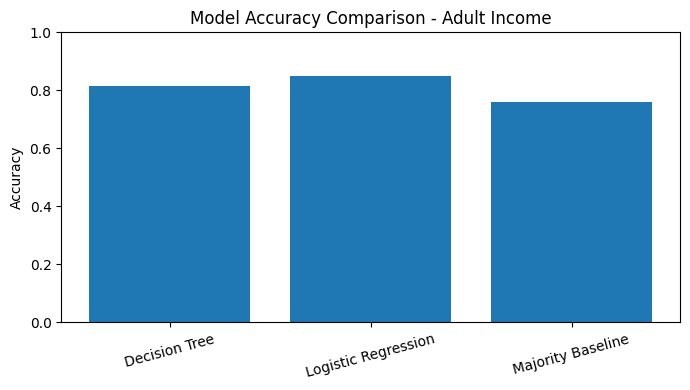

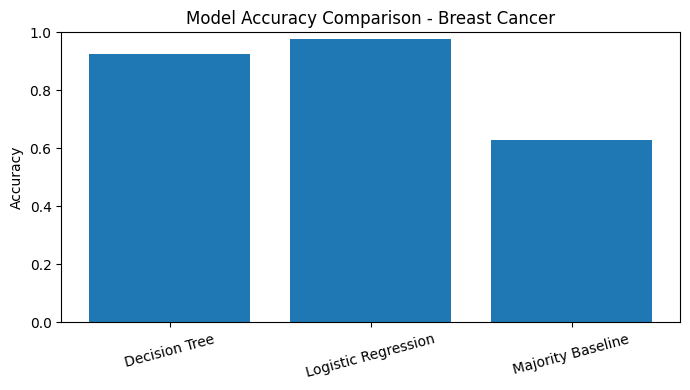

In [43]:
import matplotlib.pyplot as plt

for dataset in classification_summary["Dataset"].unique():
    data = classification_summary[
        classification_summary["Dataset"] == dataset
    ]

    plt.figure(figsize=(7, 4))
    plt.bar(data["Model"], data["Accuracy"])
    plt.title(f"Model Accuracy Comparison - {dataset}")
    plt.ylabel("Accuracy")
    plt.ylim(0, 1)
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

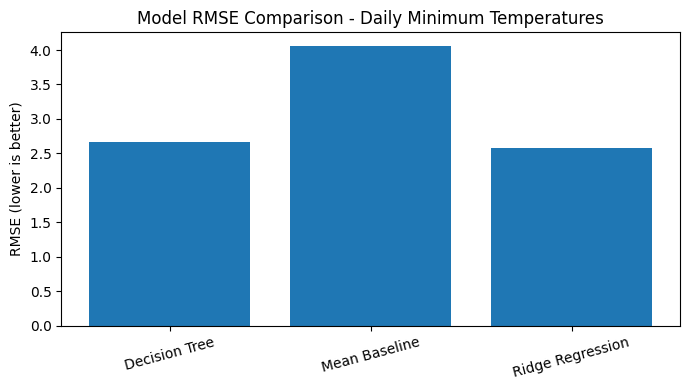

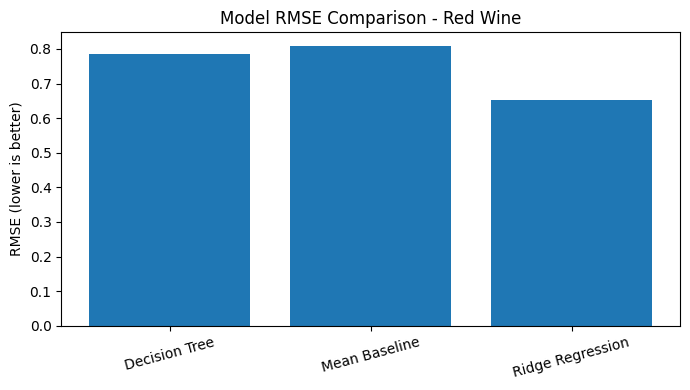

In [44]:
for dataset in regression_summary["Dataset"].unique():
    data = regression_summary[
        regression_summary["Dataset"] == dataset
    ]

    plt.figure(figsize=(7, 4))
    plt.bar(data["Model"], data["RMSE"])
    plt.title(f"Model RMSE Comparison - {dataset}")
    plt.ylabel("RMSE (lower is better)")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

In [45]:
with pd.ExcelWriter("ML_Model_Comparison_Results.xlsx") as writer:
    classification_results.to_excel(
        writer, sheet_name="Classification Results", index=False
    )
    regression_results.to_excel(
        writer, sheet_name="Regression Results", index=False
    )
    classification_summary.to_excel(
        writer, sheet_name="Classification Summary", index=False
    )
    regression_summary.to_excel(
        writer, sheet_name="Regression Summary", index=False
    )

print("Excel file created successfully!")

Excel file created successfully!


In [46]:
from google.colab import files
files.download("ML_Model_Comparison_Results.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [47]:

import sys
import numpy as np
import pandas as pd
import sklearn
import matplotlib

# 1. Record software versions
versions = pd.DataFrame({
    "Library": ["Python", "NumPy", "Pandas", "Scikit-learn", "Matplotlib"],
    "Version": [
        sys.version.split()[0],
        np.__version__,
        pd.__version__,
        sklearn.__version__,
        matplotlib.__version__
    ]
})

print("=== SOFTWARE VERSIONS ===")
print(versions.to_string(index=False))

# 2. Classification: mean and standard deviation across seeds
classification_metrics = ["Accuracy", "Precision", "Recall", "F1"]

classification_mean_std = (
    classification_results
    .groupby(["Dataset", "Model"])[classification_metrics]
    .agg(["mean", "std"])
    .round(4)
)

print("\n=== CLASSIFICATION: MEAN ± STANDARD DEVIATION ===")
print(classification_mean_std)

# 3. Regression: mean and standard deviation across seeds
regression_metrics = ["MAE", "RMSE", "R2"]

regression_mean_std = (
    regression_results
    .groupby(["Dataset", "Model"])[regression_metrics]
    .agg(["mean", "std"])
    .round(4)
)

print("\n=== REGRESSION: MEAN ± STANDARD DEVIATION ===")
print(regression_mean_std)

# 4. Save reproducibility and summary tables
with pd.ExcelWriter("Experimental_Rigor_Results.xlsx") as writer:
    versions.to_excel(writer, sheet_name="Versions", index=False)
    classification_mean_std.to_excel(
        writer, sheet_name="Classification"
    )
    regression_mean_std.to_excel(
        writer, sheet_name="Regression"
    )

print("\nSaved: Experimental_Rigor_Results.xlsx")


=== SOFTWARE VERSIONS ===
     Library Version
      Python 3.13.16
       NumPy   2.1.3
      Pandas   2.2.3
Scikit-learn   1.6.1
  Matplotlib  3.10.0

=== CLASSIFICATION: MEAN ± STANDARD DEVIATION ===
                                  Accuracy         Precision          Recall  \
                                      mean     std      mean     std    mean   
Dataset       Model                                                            
Adult Income  Decision Tree         0.8133  0.0007    0.6106  0.0025  0.6240   
              Logistic Regression   0.8511  0.0004    0.7348  0.0010  0.5975   
              Majority Baseline     0.7592  0.0000    0.0000  0.0000  0.0000   
Breast Cancer Decision Tree         0.9245  0.0080    0.9022  0.0106  0.8973   
              Logistic Regression   0.9775  0.0034    0.9814  0.0075  0.9586   
              Majority Baseline     0.6274  0.0000    0.0000  0.0000  0.0000   

                                               F1          
                

In [48]:
print("Feature variables:")
print([name for name in globals() if name.startswith("X_")])

print("\nTarget variables:")
print([name for name in globals() if name.startswith("y_")])

print("\nDataset result tables:")
print([
    name for name in globals()
    if name.endswith("_results_df")
])

Feature variables:
['X_cancer', 'X_wine', 'X_adult', 'X_temp']

Target variables:
['y_cancer', 'y_wine', 'y_adult', 'y_temp']

Dataset result tables:
['cancer_results_df', 'wine_results_df', 'adult_results_df', 'temperature_results_df']


In [50]:

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

from sklearn.model_selection import StratifiedKFold, KFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.metrics import make_scorer, f1_score

test_rows = []
SEED = 42

def classification_preprocessor(X):
    numeric_cols = X.select_dtypes(include=np.number).columns
    categorical_cols = X.select_dtypes(exclude=np.number).columns

    numeric_pipe = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler()
    )
    categorical_pipe = make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(handle_unknown="ignore")
    )

    return make_column_transformer(
        (numeric_pipe, numeric_cols),
        (categorical_pipe, categorical_cols)
    )

# Classification comparisons
for dataset, X, y in [
    ("Adult Income", X_adult, y_adult),
    ("Breast Cancer", X_cancer, y_cancer)
]:
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    preprocessor = classification_preprocessor(X)

    models = {
        "Logistic Regression": make_pipeline(
            preprocessor, LogisticRegression(max_iter=2000)
        ),
        "Decision Tree": make_pipeline(
            classification_preprocessor(X),
            DecisionTreeClassifier(random_state=SEED)
        )
    }

    scores = {}
    for name, model in models.items():
        result = cross_validate(
            model, X, y, cv=cv,
            scoring="f1_weighted"
        )
        scores[name] = result["test_score"]

    _, p = wilcoxon(
        scores["Logistic Regression"],
        scores["Decision Tree"]
    )

    test_rows.append({
        "Dataset": dataset,
        "Comparison": "Logistic Regression vs Decision Tree",
        "Metric": "Weighted F1",
        "Mean Difference": np.mean(
            scores["Logistic Regression"] - scores["Decision Tree"]
        ),
        "Wilcoxon p-value": p
    })

# Regression comparisons
for dataset, X, y in [
    ("Red Wine", X_wine, y_wine),
    ("Daily Minimum Temperatures", X_temp, y_temp)
]:
    cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

    models = {
        "Ridge Regression": Ridge(),
        "Decision Tree": DecisionTreeRegressor(random_state=SEED)
    }

    scores = {}
    for name, model in models.items():
        result = cross_validate(
            model, X, y, cv=cv,
            scoring="neg_root_mean_squared_error"
        )
        scores[name] = -result["test_score"]

    _, p = wilcoxon(
        scores["Ridge Regression"],
        scores["Decision Tree"]
    )

    test_rows.append({
        "Dataset": dataset,
        "Comparison": "Ridge Regression vs Decision Tree",
        "Metric": "RMSE (lower is better)",
        "Mean Difference": np.mean(
            scores["Ridge Regression"] - scores["Decision Tree"]
        ),
        "Wilcoxon p-value": p
    })

significance_results = pd.DataFrame(test_rows)
print(significance_results.round(5).to_string(index=False))


                   Dataset                           Comparison                 Metric  Mean Difference  Wilcoxon p-value
              Adult Income Logistic Regression vs Decision Tree            Weighted F1          0.03179            0.0625
             Breast Cancer Logistic Regression vs Decision Tree            Weighted F1          0.06375            0.0625
                  Red Wine    Ridge Regression vs Decision Tree RMSE (lower is better)         -0.11735            0.0625
Daily Minimum Temperatures    Ridge Regression vs Decision Tree RMSE (lower is better)         -0.08628            0.0625


In [51]:
print("Temperature dataset:")
print("Rows:", len(temp_df))
print("Date range:", temp_df["Date"].min(), "to", temp_df["Date"].max())

print("\nFeatures:")
print(X_temp.head())

print("\nTarget:")
print(y_temp.head())

print("\nMissing values:")
print("X_temp:", X_temp.isna().sum().sum())
print("y_temp:", y_temp.isna().sum())

Temperature dataset:
Rows: 3650
Date range: 1981-01-01 00:00:00 to 1990-12-31 00:00:00

Features:
   previous_day_temp
1               20.7
2               17.9
3               18.8
4               14.6
5               15.8

Target:
1    17.9
2    18.8
3    14.6
4    15.8
5    15.8
Name: Temp, dtype: float64

Missing values:
X_temp: 0
y_temp: 0


In [52]:

from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
import pandas as pd
import numpy as np

# Rebuild chronological feature-target pairs from the cleaned series.
# temp_clean should contain numeric Temp values and NaNs for invalid readings.
temp_ordered = temp_clean[["Date", "Temp"]].copy()
temp_ordered["previous_day_temp"] = temp_ordered["Temp"].shift(1)

temp_pairs = temp_ordered.dropna(
    subset=["Temp", "previous_day_temp"]
).copy()

X_temp_time = temp_pairs[["previous_day_temp"]]
y_temp_time = temp_pairs["Temp"]

# 5 chronological folds: each validation fold occurs after its training data.
tscv = TimeSeriesSplit(n_splits=5)

time_models = {
    "Mean Baseline": DummyRegressor(strategy="mean"),
    "Ridge Regression": Ridge(),
    "Decision Tree": DecisionTreeRegressor(random_state=42)
}

time_rows = []

for name, model in time_models.items():
    scores = cross_validate(
        model,
        X_temp_time,
        y_temp_time,
        cv=tscv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        }
    )

    time_rows.append({
        "Dataset": "Daily Minimum Temperatures",
        "Model": name,
        "MAE_mean": -scores["test_MAE"].mean(),
        "MAE_std": scores["test_MAE"].std(ddof=1),
        "RMSE_mean": -scores["test_RMSE"].mean(),
        "RMSE_std": scores["test_RMSE"].std(ddof=1),
        "R2_mean": scores["test_R2"].mean(),
        "R2_std": scores["test_R2"].std(ddof=1)
    })

temperature_time_summary = pd.DataFrame(time_rows)
print(temperature_time_summary.round(4).to_string(index=False))


                   Dataset            Model  MAE_mean  MAE_std  RMSE_mean  RMSE_std  R2_mean  R2_std
Daily Minimum Temperatures    Mean Baseline    3.1829   0.1570     3.9296    0.1594  -0.0539  0.0703
Daily Minimum Temperatures Ridge Regression    1.9825   0.0727     2.5432    0.0916   0.5578  0.0381
Daily Minimum Temperatures    Decision Tree    2.1383   0.1820     2.7440    0.2302   0.4838  0.0815


In [53]:

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import make_scorer, matthews_corrcoef
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline
import numpy as np
import pandas as pd

def classification_preprocessor(X):
    numeric_cols = X.select_dtypes(include=np.number).columns
    categorical_cols = X.select_dtypes(exclude=np.number).columns

    numeric_pipe = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler()
    )
    categorical_pipe = make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(handle_unknown="ignore")
    )

    return make_column_transformer(
        (numeric_pipe, numeric_cols),
        (categorical_pipe, categorical_cols)
    )

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

classification_data = {
    "Adult Income": (X_adult, y_adult),
    "Breast Cancer": (X_cancer, y_cancer)
}

models = {
    "Majority Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

rows = []

for dataset_name, (X, y) in classification_data.items():
    for model_name, model in models.items():
        pipeline = make_pipeline(classification_preprocessor(X), model)

        scores = cross_validate(
            pipeline, X, y, cv=cv,
            scoring={
                "accuracy": "accuracy",
                "f1_macro": "f1_macro",
                "f1_weighted": "f1_weighted",
                "roc_auc": "roc_auc",
                "mcc": make_scorer(matthews_corrcoef)
            }
        )

        rows.append({
            "Dataset": dataset_name,
            "Model": model_name,
            **{
                metric: round(scores[f"test_{metric}"].mean(), 4)
                for metric in [
                    "accuracy", "f1_macro", "f1_weighted", "roc_auc", "mcc"
                ]
            }
        })

classification_extra_metrics = pd.DataFrame(rows)
print(classification_extra_metrics.to_string(index=False))


      Dataset               Model  accuracy  f1_macro  f1_weighted  roc_auc    mcc
 Adult Income   Majority Baseline    0.7592    0.4316       0.6553   0.5000 0.0000
 Adult Income Logistic Regression    0.8513    0.7817       0.8456   0.9055 0.5700
 Adult Income       Decision Tree    0.8133    0.7461       0.8138   0.7476 0.4924
Breast Cancer   Majority Baseline    0.6274    0.3855       0.4838   0.5000 0.0000
Breast Cancer Logistic Regression    0.9737    0.9714       0.9734   0.9953 0.9447
Breast Cancer       Decision Tree    0.9104    0.9028       0.9097   0.9000 0.8079


In [55]:

import numpy as np

print("Red Wine target:")
print("Minimum:", np.min(y_wine))
print("Zero or near-zero values:", np.sum(np.isclose(y_wine, 0)))

print("\nTemperature target:")
print("Minimum:", np.min(y_temp_time))
print("Zero or near-zero values:", np.sum(np.isclose(y_temp_time, 0)))


Red Wine target:
Minimum: 3
Zero or near-zero values: 0

Temperature target:
Minimum: 0.0
Zero or near-zero values: 2


In [57]:

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import KFold, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor

regression_data = {
    "Red Wine": (
        X_wine, y_wine,
        KFold(n_splits=5, shuffle=True, random_state=42)
    ),
    "Daily Minimum Temperatures": (
        X_temp_time, y_temp_time,
        TimeSeriesSplit(n_splits=5)
    )
}

regression_models = {
    "Mean Baseline": DummyRegressor(strategy="mean"),
    "Ridge Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        Ridge()
    ),
    "Decision Tree": DecisionTreeRegressor(random_state=42)
}

mape_rows = []

for dataset_name, (X, y, cv) in regression_data.items():
    X = X.reset_index(drop=True) if hasattr(X, "reset_index") else X
    y = np.asarray(y)
    predictions = np.full(len(y), np.nan)

    for train_idx, test_idx in cv.split(X, y):
        for model_name, model in regression_models.items():
            fitted_model = clone(model)
            fitted_model.fit(X.iloc[train_idx], y[train_idx])
            fold_predictions = fitted_model.predict(X.iloc[test_idx])

            # Store predictions separately for each model below.
            key = (dataset_name, model_name)
            if key not in locals().get("prediction_store", {}):
                pass

    # Generate out-of-fold predictions separately for each model.
    for model_name, model in regression_models.items():
        predictions = np.full(len(y), np.nan)

        for train_idx, test_idx in cv.split(X, y):
            fitted_model = clone(model)
            fitted_model.fit(X.iloc[train_idx], y[train_idx])
            predictions[test_idx] = fitted_model.predict(X.iloc[test_idx])

        valid = (~np.isclose(y, 0)) & np.isfinite(predictions)

        mape = (
            np.mean(np.abs((y[valid] - predictions[valid]) / y[valid])) * 100
            if valid.any() else np.nan
        )

        mape_rows.append({
            "Dataset": dataset_name,
            "Model": model_name,
            "MAPE_percent": round(mape, 2),
            "Excluded_zero_targets": int(np.isclose(y, 0).sum())
        })

mape_results = pd.DataFrame(mape_rows)
print(mape_results.to_string(index=False))


                   Dataset            Model  MAPE_percent  Excluded_zero_targets
                  Red Wine    Mean Baseline         12.51                      0
                  Red Wine Ridge Regression          9.29                      0
                  Red Wine    Decision Tree          8.31                      0
Daily Minimum Temperatures    Mean Baseline         43.00                      2
Daily Minimum Temperatures Ridge Regression         24.25                      2
Daily Minimum Temperatures    Decision Tree         25.45                      2


In [58]:

from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
import pandas as pd

# Build lag features in chronological order.
ablation_df = temp_clean[["Date", "Temp"]].copy()
ablation_df["lag_1"] = ablation_df["Temp"].shift(1)
ablation_df["lag_2"] = ablation_df["Temp"].shift(2)
ablation_df["lag_3"] = ablation_df["Temp"].shift(3)

ablation_results = []

feature_sets = {
    "1-day lag": ["lag_1"],
    "2-day lags": ["lag_1", "lag_2"],
    "3-day lags": ["lag_1", "lag_2", "lag_3"]
}

for feature_name, features in feature_sets.items():
    data = ablation_df.dropna(subset=features + ["Temp"])
    X = data[features]
    y = data["Temp"]

    scores = cross_validate(
        make_pipeline(StandardScaler(), Ridge()),
        X, y,
        cv=TimeSeriesSplit(n_splits=5),
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        }
    )

    ablation_results.append({
        "Features": feature_name,
        "MAE": -scores["test_MAE"].mean(),
        "RMSE": -scores["test_RMSE"].mean(),
        "R2": scores["test_R2"].mean()
    })

ablation_results = pd.DataFrame(ablation_results)
print(ablation_results.round(4).to_string(index=False))


  Features    MAE   RMSE     R2
 1-day lag 1.9824 2.5431 0.5578
2-day lags 1.9735 2.5316 0.5614
3-day lags 1.9432 2.4844 0.5775


In [59]:

ablation_results.to_csv("temperature_ablation_results.csv", index=False)

print("Saved temperature_ablation_results.csv")
print(ablation_results.round(4))


Saved temperature_ablation_results.csv
     Features     MAE    RMSE      R2
0   1-day lag  1.9824  2.5431  0.5578
1  2-day lags  1.9735  2.5316  0.5614
2  3-day lags  1.9432  2.4844  0.5775


In [60]:

import os
import shutil

project_dir = "ML-Model-Comparison"

folders = [
    "notebooks",
    "results",
    "figures",
    "paper"
]

for folder in folders:
    os.makedirs(os.path.join(project_dir, folder), exist_ok=True)

# Save the ablation results inside the project
ablation_results.to_csv(
    os.path.join(project_dir, "results", "temperature_ablation_results.csv"),
    index=False
)

print("Project folders created successfully!")
for root, dirs, files in os.walk(project_dir):
    print(root, "->", files)


Project folders created successfully!
ML-Model-Comparison -> []
ML-Model-Comparison/paper -> []
ML-Model-Comparison/notebooks -> []
ML-Model-Comparison/results -> ['temperature_ablation_results.csv']
ML-Model-Comparison/figures -> []


In [61]:

import os

results_dir = "ML-Model-Comparison/results"
os.makedirs(results_dir, exist_ok=True)

# Save classification results
classification_results.to_csv(
    f"{results_dir}/classification_results.csv", index=False
)

# Save regression results
regression_results.to_csv(
    f"{results_dir}/regression_results.csv", index=False
)

# Save summary tables
classification_summary.to_csv(
    f"{results_dir}/classification_summary.csv", index=False
)

regression_summary.to_csv(
    f"{results_dir}/regression_summary.csv", index=False
)

classification_mean_std.to_csv(
    f"{results_dir}/classification_mean_std.csv"
)

regression_mean_std.to_csv(
    f"{results_dir}/regression_mean_std.csv"
)

# Save the additional classification metrics
classification_extra_metrics.to_csv(
    f"{results_dir}/classification_extra_metrics.csv", index=False
)

# Save temperature validation and ablation results
temperature_time_summary.to_csv(
    f"{results_dir}/temperature_time_series_results.csv", index=False
)

ablation_results.to_csv(
    f"{results_dir}/temperature_ablation_results.csv", index=False
)

# Save MAPE results
mape_results.to_csv(
    f"{results_dir}/regression_mape_results.csv", index=False
)

print("Saved result files:")
print(sorted(os.listdir(results_dir)))


Saved result files:
['classification_extra_metrics.csv', 'classification_mean_std.csv', 'classification_results.csv', 'classification_summary.csv', 'regression_mape_results.csv', 'regression_mean_std.csv', 'regression_results.csv', 'regression_summary.csv', 'temperature_ablation_results.csv', 'temperature_time_series_results.csv']


In [62]:

import os

project_dir = "ML-Model-Comparison"

requirements = """numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
matplotlib==3.10.0
"""

readme = """# Machine Learning Model Comparison

## Overview
This project compares baseline and machine learning models across four datasets:
- Adult Income — classification
- Breast Cancer — classification
- Red Wine Quality — regression
- Daily Minimum Temperatures — regression and time-series forecasting

## Research Objective
To compare simple baseline models with Logistic Regression, Decision Trees, and Ridge Regression using multiple evaluation metrics and validation strategies.

## Models
### Classification
- Majority Class Baseline
- Logistic Regression
- Decision Tree Classifier

### Regression
- Mean Baseline
- Ridge Regression
- Decision Tree Regressor

## Evaluation
Classification metrics include accuracy, macro F1, weighted F1, ROC-AUC, and Matthews Correlation Coefficient (MCC).

Regression metrics include MAE, RMSE, R-squared, and MAPE.

The temperature experiment uses chronological TimeSeriesSplit validation. An ablation study compares Ridge Regression using one, two, and three previous-day temperature features.

## Reproducibility
Experiments use fixed random seeds where applicable. Software versions are recorded in the project results.

## Repository Structure
- `notebooks/` — experiment notebook
- `results/` — CSV result tables
- `figures/` — experiment plots
- `paper/` — manuscript

## Current Findings
Logistic Regression performs strongly on both classification datasets. Ridge Regression performs best on the temperature time-series experiment, while the Decision Tree has the lowest pooled out-of-fold MAPE on Red Wine Quality.

## Limitations
The current experiments use a limited set of models and features. Results depend on dataset preprocessing and validation strategy. Further work should include additional baselines, confidence intervals or suitable paired comparisons, and more extensive hyperparameter evaluation.

## Status
Research project in progress. Results should be interpreted as experimental findings, not universal claims about model performance.
"""

with open(f"{project_dir}/requirements.txt", "w") as f:
    f.write(requirements)

with open(f"{project_dir}/README.md", "w") as f:
    f.write(readme)

print("Created README.md and requirements.txt")
print(os.listdir(project_dir))


Created README.md and requirements.txt
['paper', 'requirements.txt', 'notebooks', 'results', 'README.md', 'figures']
